In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error

In [3]:
df = pd.read_csv(r"Downloads/archive (7)/employee_performance.csv")

In [4]:
df.head()

,Employee_ID,Age,Gender,Department,Experience_Years,Performance_Score,Salary
0,E0524,49,Female,Operations,5.6,67.8,33013.0
1,E0603,55,Female,Sales,5.5,NaN,42640.0
2,E0527,29,Female,Sales,10.7,68.8,72180.0
3,E0032,30,Female,Operations,9.8,NaN,65750.0
4,E0617,58,Male,Sales,11.5,72.8,74830.0


In [5]:
df.tail()

,Employee_ID,Age,Gender,Department,Experience_Years,Performance_Score,Salary
1015,E0107,26,Male,IT,9.2,83.9,51410.0
1016,E0271,40,Female,Finance,4.8,77.4,48858.0
1017,E0861,47,Male,Operations,2.0,76.5,24647.0
1018,E0436,57,Male,HR,1.8,55.7,26744.0
1019,E0103,58,Male,IT,7.9,86.5,53764.0


In [6]:
df.shape

(1020, 7)

In [7]:
df.columns.tolist()

['Employee_ID',
 'Age',
 'Gender',
 'Department',
 'Experience_Years',
 'Performance_Score',
 'Salary']

In [8]:
df.dtypes

Employee_ID           object
Age                    int64
Gender                object
Department            object
Experience_Years     float64
Performance_Score    float64
Salary               float64
dtype: object

In [9]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1020 entries, 0 to 1019
Data columns (total 7 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   Employee_ID        1020 non-null   object 
 1   Age                1020 non-null   int64  
 2   Gender             1020 non-null   object 
 3   Department         1020 non-null   object 
 4   Experience_Years   988 non-null    float64
 5   Performance_Score  990 non-null    float64
 6   Salary             1020 non-null   float64
dtypes: float64(3), int64(1), object(3)
memory usage: 55.9+ KB


In [10]:
df.describe()

,Age,Experience_Years,Performance_Score,Salary
count,1020.000000,988.000000,990.000000,1020.000000
mean,40.898039,7.209919,69.755657,52905.790196
std,11.160063,3.070575,9.935075,33016.717394
min,22.000000,0.000000,37.600000,5000.000000
25%,31.000000,5.200000,63.025000,38867.750000
50%,42.000000,7.250000,70.050000,50595.500000
75%,50.000000,9.200000,76.675000,60984.250000
max,59.000000,16.800000,97.500000,400000.000000


In [11]:
df.isnull().sum()

Employee_ID           0
Age                   0
Gender                0
Department            0
Experience_Years     32
Performance_Score    30
Salary                0
dtype: int64

In [12]:
df['Experience_Years'].fillna(df['Experience_Years'].median(),inplace=True)
df['Performance_Score'].fillna(df['Performance_Score'].median(),inplace=True)

C:\Users\hp\AppData\Local\Temp\ipykernel_8048\3082128682.py:1: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  df['Experience_Years'].fillna(df['Experience_Years'].median(),inplace=True)
C:\Users\hp\AppData\Local\Temp\ipykernel_8048\3082128682.py:2: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves 

In [13]:
df.isnull().sum()

Employee_ID          0
Age                  0
Gender               0
Department           0
Experience_Years     0
Performance_Score    0
Salary               0
dtype: int64

In [14]:
df.duplicated().sum()

20

In [15]:
df = df.drop_duplicates()

In [16]:
df.duplicated().sum()

0

In [17]:
df.shape

(1000, 7)

In [18]:
print(df.dtypes)

Employee_ID           object
Age                    int64
Gender                object
Department            object
Experience_Years     float64
Performance_Score    float64
Salary               float64
dtype: object


In [19]:
df['Gender'].value_counts()

Gender
Male      504
Female    496
Name: count, dtype: int64

In [20]:
df['Department'].value_counts()

Department
Marketing     185
Sales         178
Operations    172
Finance       170
HR            158
IT            137
Name: count, dtype: int64

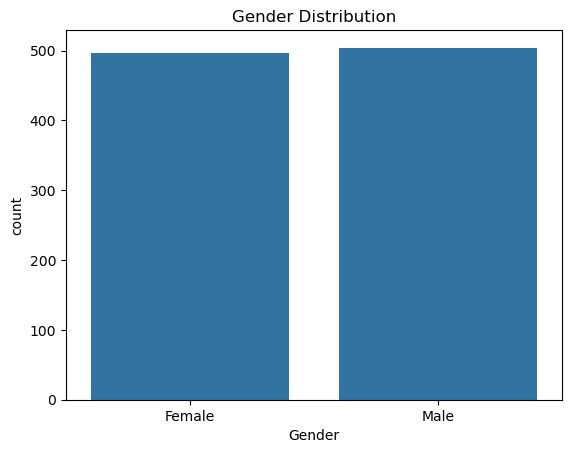

In [21]:
sns.countplot(data=df, x='Gender')
plt.title('Gender Distribution')
plt.show()

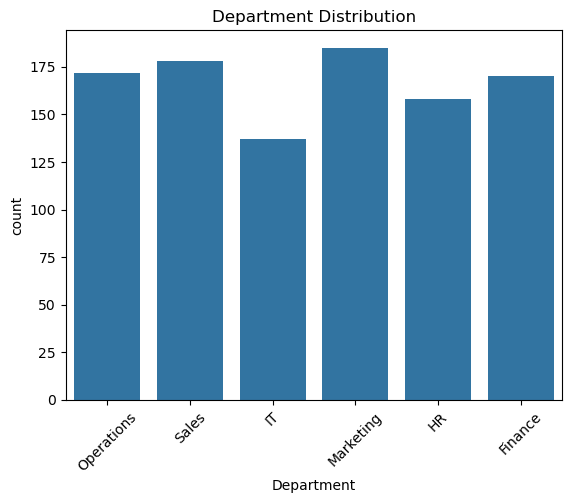

In [22]:
sns.countplot(data=df, x='Department')
plt.title('Department Distribution')
plt.xticks(rotation=45)
plt.show()

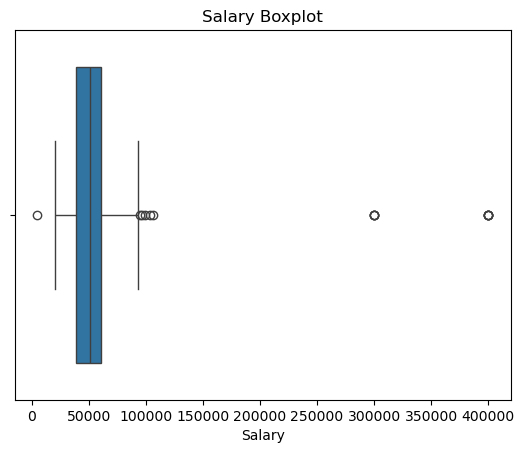

In [23]:
sns.boxplot(x=df['Salary'])
plt.title('Salary Boxplot')
plt.show()

In [24]:
df[df['Salary'] >= 200000][['Employee_ID', 'Age', 'Gender', 'Department','Experience_Years', 'Performance_Score', 'Salary']]

,Employee_ID,Age,Gender,Department,Experience_Years,Performance_Score,Salary
118,E0758,29,Female,HR,5.6,80.6,300000.0
386,E0165,53,Female,Marketing,9.5,76.9,300000.0
408,E0674,26,Female,HR,10.1,79.2,400000.0
463,E0224,41,Male,Sales,11.0,72.4,400000.0
492,E0418,34,Male,HR,6.0,71.5,400000.0
516,E0427,50,Male,IT,10.9,67.0,300000.0
519,E0976,45,Female,Marketing,11.9,56.3,300000.0
819,E0578,34,Male,Marketing,4.6,64.2,400000.0
898,E0493,30,Female,Marketing,8.1,71.5,400000.0


In [25]:
Q1 = df['Salary'].quantile(0.25)
Q3 = df['Salary'].quantile(0.75)

IQR = Q3 - Q1

lower_limit = Q1 - 1.5 * IQR
upper_limit = Q3 + 1.5 * IQR

print("Q1:", Q1)
print("Q3:", Q3)
print("IQR:", IQR)
print("Lower limit:", lower_limit)
print("Upper limit:", upper_limit)

Q1: 38980.0
Q3: 61079.25
IQR: 22099.25
Lower limit: 5831.125
Upper limit: 94228.125


In [26]:
df_clean = df[(df['Salary'] >= lower_limit) & (df['Salary'] <= upper_limit)].copy()

In [27]:
print("Original shape:", df.shape)
print("Cleaned shape:", df_clean.shape)

Original shape: (1000, 7)
Cleaned shape: (985, 7)


In [28]:
df_clean['Experience_Years'] = df_clean['Experience_Years'].fillna(
    df_clean['Experience_Years'].median()
)

df_clean['Performance_Score'] = df_clean['Performance_Score'].fillna(
    df_clean['Performance_Score'].median()
)

In [29]:
print(df_clean.isnull().sum())

Employee_ID          0
Age                  0
Gender               0
Department           0
Experience_Years     0
Performance_Score    0
Salary               0
dtype: int64


In [30]:
df_clean = df_clean.drop_duplicates()

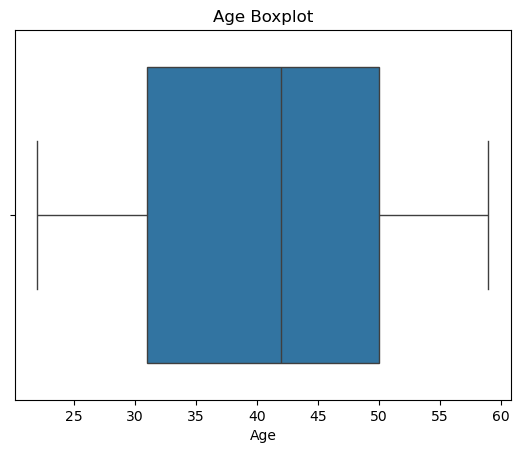

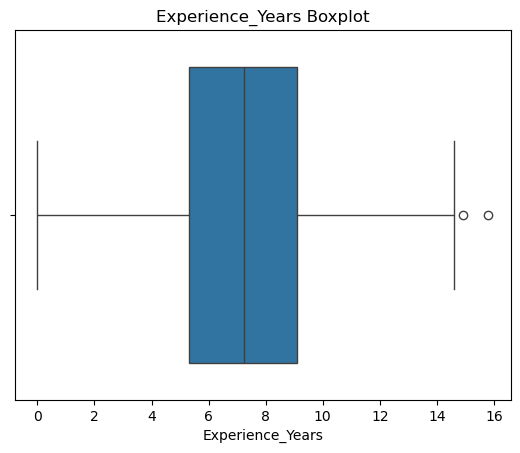

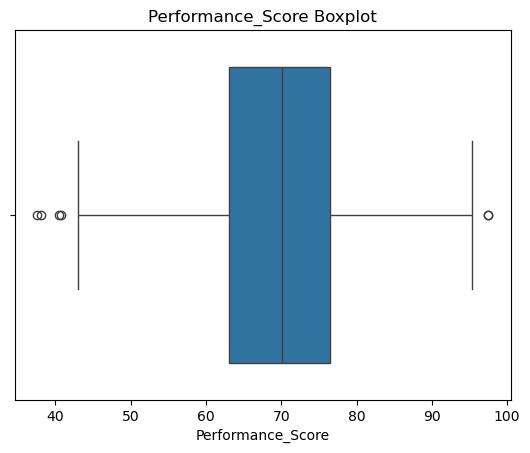

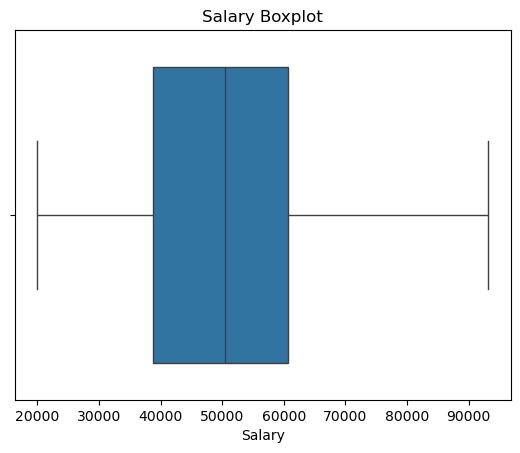

In [31]:
numerical_columns = ['Age','Experience_Years','Performance_Score','Salary']
for column in numerical_columns:
    plt.figure()
    sns.boxplot(x=df_clean[column])
    plt.title(f'{column} Boxplot')
    plt.show()

In [192]:
corr = df_clean.select_dtypes(include='number').corr()
print(corr)

                        Age  Experience_Years  Performance_Score    Salary
Age                1.000000          0.016935           0.049181  0.034501
Experience_Years   0.016935          1.000000           0.052095  0.927505
Performance_Score  0.049181          0.052095           1.000000  0.180192
Salary             0.034501          0.927505           0.180192  1.000000


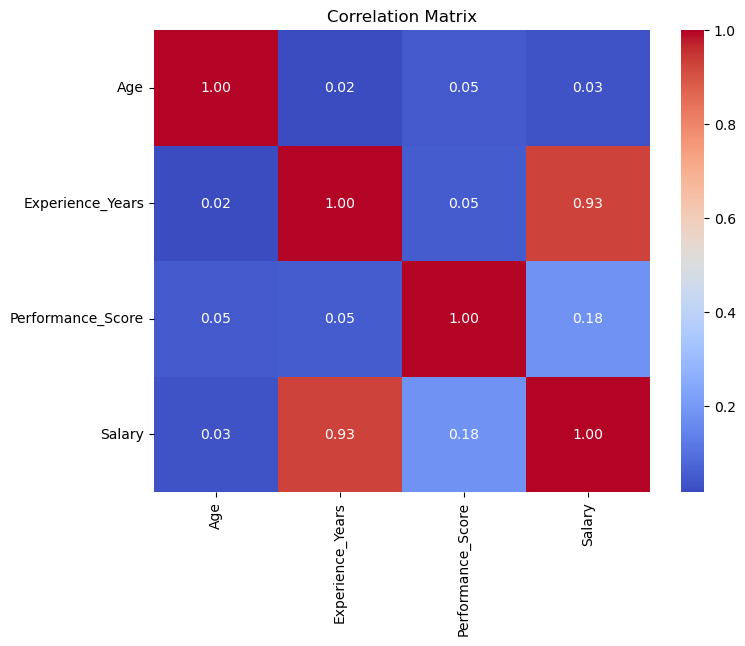

In [193]:
plt.figure(figsize=(8,6))
sns.heatmap(corr,annot=True,cmap='coolwarm',fmt='.2f')
plt.title('Correlation Matrix')
plt.show()

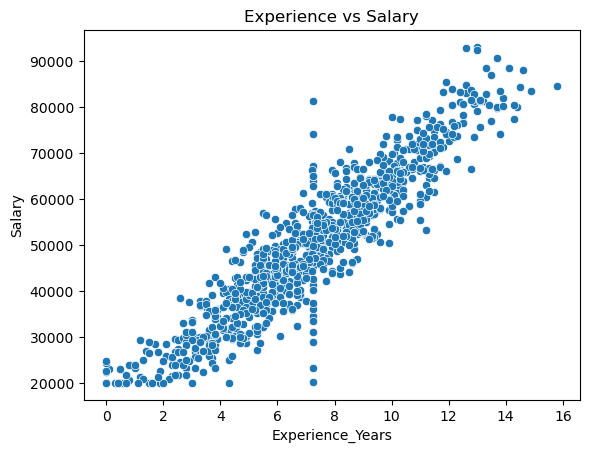

In [195]:
sns.scatterplot(data=df_clean, x='Experience_Years', y='Salary')
plt.title('Experience vs Salary')
plt.show()

In [34]:
X = df_clean.drop(['Employee_ID', 'Salary'], axis=1)

y = df_clean['Salary']

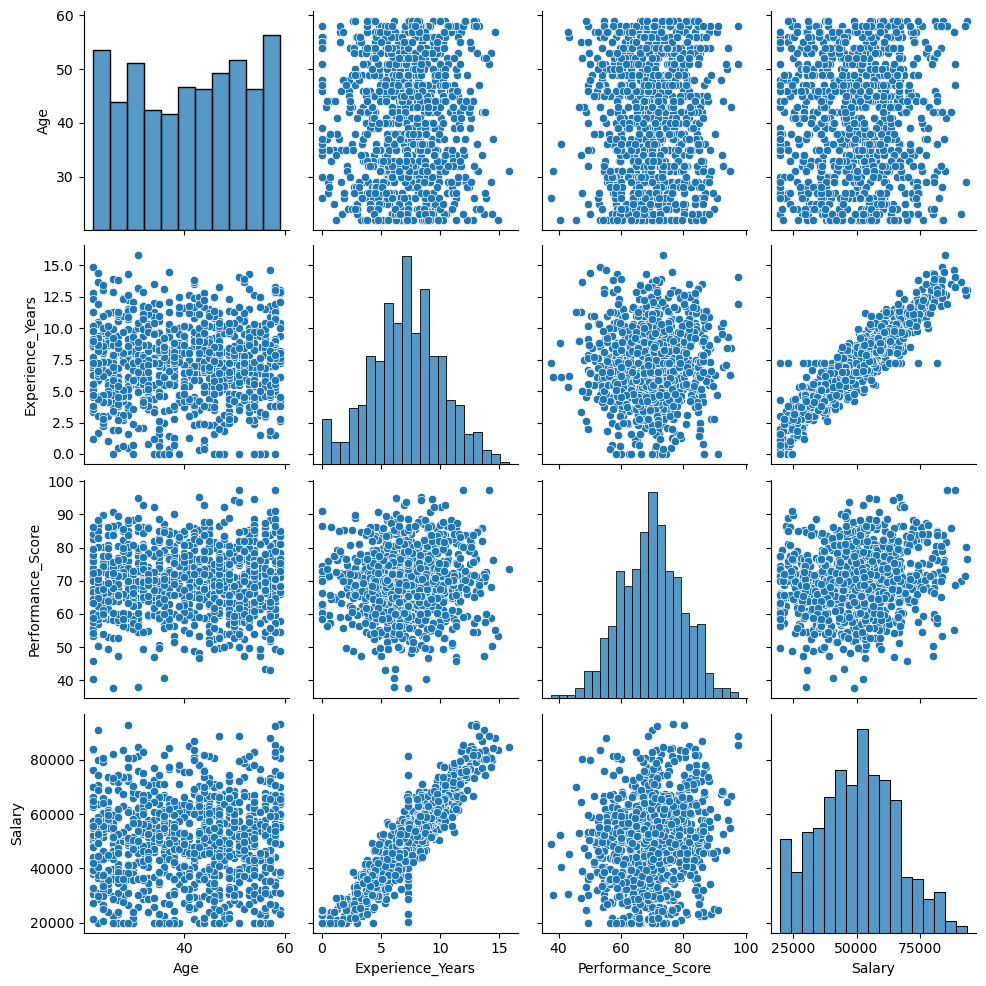

In [36]:
sns.pairplot(df_clean)
plt.show()

In [199]:
print(X.columns)

Index(['Age', 'Gender', 'Department', 'Experience_Years', 'Performance_Score'], dtype='object')


In [200]:
X = pd.get_dummies(X, drop_first=True)

In [201]:
X.head()

,Age,Experience_Years,Performance_Score,Gender_Male,Department_HR,Department_IT,Department_Marketing,Department_Operations,Department_Sales
0,49,5.6,67.80,False,False,False,False,True,False
1,55,5.5,70.05,False,False,False,False,False,True
2,29,10.7,68.80,False,False,False,False,False,True
3,30,9.8,70.05,False,False,False,False,True,False
4,58,11.5,72.80,True,False,False,False,False,True


In [202]:
X.dtypes

Age                        int64
Experience_Years         float64
Performance_Score        float64
Gender_Male                 bool
Department_HR               bool
Department_IT               bool
Department_Marketing        bool
Department_Operations       bool
Department_Sales            bool
dtype: object

In [203]:
print("X shape:", X.shape)
print("y shape:", y.shape)

X shape: (985, 9)
y shape: (985,)


In [204]:
X_train, X_test, y_train, y_test = train_test_split(X,y,test_size=0.2,random_state=2)

In [205]:
print(X_train.shape)
print(X_test.shape)

(788, 9)
(197, 9)


In [206]:
model = LinearRegression()
model.fit(X_train, y_train)

LinearRegression()

In [207]:
train_predictions = model.predict(X_train)
test_predictions = model.predict(X_test)

In [208]:
from sklearn.metrics import r2_score
train_r2 = r2_score(y_train, train_predictions)
test_r2 = r2_score(y_test, test_predictions)
print("Train R2:", train_r2)
print("Test R2:", test_r2)

Train R2: 0.8802431085330589
Test R2: 0.8666480079012938


In [209]:
from sklearn.model_selection import cross_val_score
scores = cross_val_score(model,X,y,cv=5)
print(scores)
scores.mean()

[0.8623892  0.88633921 0.89179697 0.87844426 0.85332135]


0.8744581978430668

In [213]:
import statsmodels.formula.api as smf
model1 = smf.ols('Salary ~ Age + Experience_Years + Performance_Score',data=df_clean).fit()
model1.summary()

<class 'statsmodels.iolib.summary.Summary'>
"""
                            OLS Regression Results                            
==============================================================================
Dep. Variable:                 Salary   R-squared:                       0.878
Model:                            OLS   Adj. R-squared:                  0.877
Method:                 Least Squares   F-statistic:                     2350.
Date:                Fri, 04 Sep 2026   Prob (F-statistic):               0.00
Time:                        23:16:45   Log-Likelihood:                -9871.3
No. Observations:                 985   AIC:                         1.975e+04
Df Residuals:                     981   BIC:                         1.977e+04
Df Model:                           3                                         
Covariance Type:            nonrobust                                         
=====================================================================================
                        coef    std err          t      P>|t|      [0.025      0.975]
-------------------------------------------------------------------------------------
Intercept           276.8510   1417.618      0.195      0.845   -2505.061    3058.763
Age                  17.3575     15.590      1.113      0.266     -13.237      47.952
Experience_Years   4810.0372     58.397     82.369      0.000    4695.441    4924.634
Performance_Score   208.8181     17.746     11.767      0.000     173.993     243.643
==============================================================================
Omnibus:                       70.394   Durbin-Watson:                   1.812
Prob(Omnibus):                  0.000   Jarque-Bera (JB):              315.867
Skew:                          -0.094   Prob(JB):                     2.57e-69
Kurtosis:                       5.768   Cond. No.                         668.
==============================================================================

Notes:
[1] Standard Errors assume that the covariance matrix of the errors is correctly specified.
"""

In [223]:
mae = mean_absolute_error(y_test, test_predictions)

print("Test MAE:", mae)

Test MAE: 4255.8893888502325


In [225]:
mse = mean_squared_error(y_test, test_predictions)

print("Test MSE:", mse)

Test MSE: 31641230.160782356


In [227]:
rmse = np.sqrt(mse)

print("Test RMSE:", rmse)

Test RMSE: 5625.053791812337


In [228]:
comparison = pd.DataFrame({
    'Actual Salary': y_test.values,
    'Predicted Salary': test_predictions
})

comparison.head(10)

,Actual Salary,Predicted Salary
0,56904.0,57365.306627
1,58175.0,50641.901049
2,21727.0,28837.051624
3,49147.0,37712.694760
4,83455.0,84032.440765
5,46661.0,51084.432760
6,49287.0,55248.886484
7,51628.0,59034.829415
8,37142.0,42467.552689
9,58842.0,63578.367342


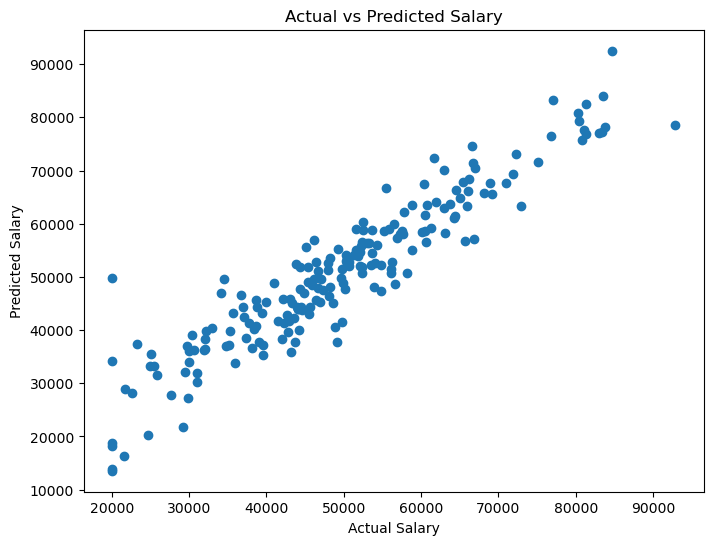

In [229]:
plt.figure(figsize=(8,6))

plt.scatter(y_test, test_predictions)

plt.xlabel('Actual Salary')
plt.ylabel('Predicted Salary')
plt.title('Actual vs Predicted Salary')

plt.show()

In [230]:
residuals = y_test - test_predictions

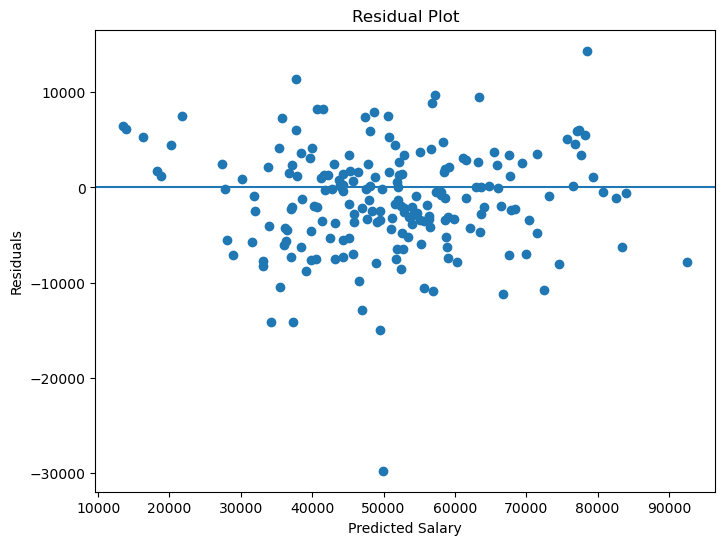

In [231]:
plt.figure(figsize=(8,6))

plt.scatter(test_predictions, residuals)

plt.axhline(y=0)

plt.xlabel('Predicted Salary')
plt.ylabel('Residuals')
plt.title('Residual Plot')

plt.show()

In [238]:
print("Number of X columns:", len(X.columns))
print("Number of model coefficients:", len(model.coef_))

print("\nX columns:")
print(X.columns)

print("\nCoefficients:")
print(model.coef_)

Number of X columns: 3
Number of model coefficients: 9

X columns:
Index(['Age', 'Experience_Years', 'Performance_Score'], dtype='object')

Coefficients:
[  13.38551116 4818.664183    200.03893479 -173.72070989 -354.29775334
  -60.8232609  -259.12500549  -41.95960492   74.83127654]


In [239]:
model.fit(X_train, y_train)

LinearRegression()

In [240]:
model.coef_

array([  13.38551116, 4818.664183  ,  200.03893479, -173.72070989,
       -354.29775334,  -60.8232609 , -259.12500549,  -41.95960492,
         74.83127654])

In [241]:
coefficients = pd.DataFrame({
    'Feature': X_train.columns,
    'Coefficient': model.coef_
})

coefficients = coefficients.sort_values(
    by='Coefficient',
    ascending=False
)

coefficients

,Feature,Coefficient
1,Experience_Years,4818.664183
2,Performance_Score,200.038935
8,Department_Sales,74.831277
0,Age,13.385511
7,Department_Operations,-41.959605
5,Department_IT,-60.823261
3,Gender_Male,-173.720710
6,Department_Marketing,-259.125005
4,Department_HR,-354.297753


In [243]:
print("Intercept:", model.intercept_)

Intercept: 1451.5086784480227


In [245]:
X_vif = X_train.astype(float)

In [247]:
from statsmodels.stats.outliers_influence import variance_inflation_factor

vif_data = pd.DataFrame()

vif_data['Feature'] = X_vif.columns

vif_data['VIF'] = [
    variance_inflation_factor(X_vif.values, i)
    for i in range(X_vif.shape[1])
]

vif_data

,Feature,VIF
0,Age,13.276134
1,Experience_Years,6.548888
2,Performance_Score,19.661736
3,Gender_Male,2.029865
4,Department_HR,1.886353
5,Department_IT,1.793896
6,Department_Marketing,2.000384
7,Department_Operations,1.991386
8,Department_Sales,2.057866


In [248]:
final_model = smf.ols(formula='Salary ~ Experience_Years + Performance_Score',data=df_clean).fit()
final_model.summary()

<class 'statsmodels.iolib.summary.Summary'>
"""
                            OLS Regression Results                            
==============================================================================
Dep. Variable:                 Salary   R-squared:                       0.878
Model:                            OLS   Adj. R-squared:                  0.877
Method:                 Least Squares   F-statistic:                     3524.
Date:                Sat, 05 Sep 2026   Prob (F-statistic):               0.00
Time:                        00:06:40   Log-Likelihood:                -9871.9
No. Observations:                 985   AIC:                         1.975e+04
Df Residuals:                     982   BIC:                         1.976e+04
Df Model:                           2                                         
Covariance Type:            nonrobust                                         
=====================================================================================
                        coef    std err          t      P>|t|      [0.025      0.975]
-------------------------------------------------------------------------------------
Intercept           913.6136   1297.283      0.704      0.481   -1632.151    3459.378
Experience_Years   4810.9741     58.398     82.383      0.000    4696.376    4925.573
Performance_Score   209.7739     17.728     11.833      0.000     174.985     244.562
==============================================================================
Omnibus:                       70.757   Durbin-Watson:                   1.813
Prob(Omnibus):                  0.000   Jarque-Bera (JB):              319.108
Skew:                          -0.094   Prob(JB):                     5.09e-70
Kurtosis:                       5.782   Cond. No.                         529.
==============================================================================

Notes:
[1] Standard Errors assume that the covariance matrix of the errors is correctly specified.
"""